In [2]:
import random
from datetime import datetime, timedelta
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

## Projeto Fase 2 - Módulo de Gerenciamento de Pouso e Estabilização de Base (MGPEB)

In [3]:
%reload_ext watermark
%watermark -a "Ciência da Computação - FIAP"
%watermark -a "Matheus dos Anjos de Oliveira, Isabelle Marques Guzzo e Nathan Kaique Soares Gomes" --iversions

Author: Ciência da Computação - FIAP

Author: Matheus dos Anjos de Oliveira, Isabelle Marques Guzzo e Nathan Kaique Soares Gomes

matplotlib: 3.10.8
numpy     : 2.4.2
pandas    : 3.0.1
seaborn   : 0.13.2



In [3]:
# 1. Configuração Inicial
modulos = ["Suporte Médico", "Habitação", "Logística", "Energia", "Laboratório"]
dados_telemetria = []
tempo_atual = datetime(2026, 10, 9, 18, 0, 0)

# Estado do Foguete
foguete = {
    "altitude_km": 0.0,
    "velocidade_kmh": 0.0,
    "fase": "1 - Decolagem Terra"
}

# Dicionário
estado_modulos = {
    m: {"status": "Acoplado", "altitude_km": 0.0, "combustivel": 100.0, "temp_interna": 22.0} 
    for m in modulos
}

# 2. Motor do Tempo
for tick in range(350):
    tempo_atual += timedelta(minutes=5)
    
    # --- A. FÍSICA DO FOGUETE ---
    if tick < 50:
        foguete["fase"] = "1 - Subida Terrestre"
        foguete["altitude_km"] += random.uniform(10, 50)
        foguete["velocidade_kmh"] = random.uniform(15000, 28000)
    elif tick < 150:
        foguete["fase"] = "2 - Trânsito Espacial"
        foguete["altitude_km"] += random.uniform(100, 500)
        foguete["velocidade_kmh"] = random.uniform(35000, 40000)
    elif tick < 200:
        foguete["fase"] = "3 - Órbita de Marte"
        foguete["altitude_km"] = 400.0 + random.uniform(-2, 2) # Orbita a 400km de altura
        foguete["velocidade_kmh"] = random.uniform(12000, 14000)
    else:
        foguete["fase"] = "4 - Procedimento de Pouso"
        foguete["altitude_km"] = 400.0 + random.uniform(-2, 2) # Foguete continua orbitando
        
    # --- B. FÍSICA INDIVIDUAL DOS MÓDULOS ---
    for i, nome_modulo in enumerate(modulos):
        mod = estado_modulos[nome_modulo]
        
        # Lógica de Ejeção
        if foguete["fase"] == "4 - Procedimento de Pouso":
            tick_de_ejecao = 200 + (i * 25)
            
            if tick == tick_de_ejecao:
                mod["status"] = "Ejetado/Descendo"
                mod["altitude_km"] = foguete["altitude_km"]
                
            # Dinâmica de queda individual
            if mod["status"] == "Ejetado/Descendo":
                mod["altitude_km"] -= random.uniform(10, 25)
                mod["combustivel"] -= random.uniform(1.0, 3.5)
                mod["temp_interna"] += random.uniform(-0.5, 0.2)
                
                # Bateu no chão!
                if mod["altitude_km"] <= 0:
                    mod["altitude_km"] = 0
                    mod["status"] = "Pousado"
                    mod["combustivel"] = round(mod["combustivel"], 2)
        
        # --- C. REGISTRO DO LOG ---
        alt_atual = foguete["altitude_km"] if mod["status"] == "Acoplado" else mod["altitude_km"]
        vel_atual = foguete["velocidade_kmh"] if mod["status"] == "Acoplado" else (random.uniform(500, 2000) if mod["status"] == "Ejetado/Descendo" else 0.0)
        
        dados_telemetria.append({
            "Timestamp": tempo_atual.strftime("%Y-%m-%d %H:%M:%S"),
            "Modulo": nome_modulo,
            "Fase_Missao": foguete["fase"],
            "Status": mod["status"],
            "Altitude_km": round(alt_atual, 2),
            "Velocidade_kmh": round(vel_atual, 2),
            "Combustivel_%": round(mod["combustivel"], 2),
            "Temp_Interna_C": round(mod["temp_interna"], 2)
        })

df_telemetria = pd.DataFrame(dados_telemetria)
df_telemetria.to_csv("telemetria_aurora_siger.csv", index=False)

print(f"O arquivo telemetria_aurora_siger.csv' criado com {len(df_telemetria)} linhas.")
print(df_telemetria.head(10))

O arquivo telemetria_aurora_siger.csv' criado com 1750 linhas.
             Timestamp          Modulo           Fase_Missao    Status  \
0  2026-10-09 18:05:00  Suporte Médico  1 - Subida Terrestre  Acoplado   
1  2026-10-09 18:05:00       Habitação  1 - Subida Terrestre  Acoplado   
2  2026-10-09 18:05:00       Logística  1 - Subida Terrestre  Acoplado   
3  2026-10-09 18:05:00         Energia  1 - Subida Terrestre  Acoplado   
4  2026-10-09 18:05:00     Laboratório  1 - Subida Terrestre  Acoplado   
5  2026-10-09 18:10:00  Suporte Médico  1 - Subida Terrestre  Acoplado   
6  2026-10-09 18:10:00       Habitação  1 - Subida Terrestre  Acoplado   
7  2026-10-09 18:10:00       Logística  1 - Subida Terrestre  Acoplado   
8  2026-10-09 18:10:00         Energia  1 - Subida Terrestre  Acoplado   
9  2026-10-09 18:10:00     Laboratório  1 - Subida Terrestre  Acoplado   

   Altitude_km  Velocidade_kmh  Combustivel_%  Temp_Interna_C  
0        27.14        24161.71          100.0            2

In [4]:
df_telemetria.head(4)

,Timestamp,Modulo,Fase_Missao,Status,Altitude_km,Velocidade_kmh,Combustivel_%,Temp_Interna_C
0,2026-10-09 18:05:00,Suporte Médico,1 - Subida Terrestre,Acoplado,27.14,24161.71,100.0,22.0
1,2026-10-09 18:05:00,Habitação,1 - Subida Terrestre,Acoplado,27.14,24161.71,100.0,22.0
2,2026-10-09 18:05:00,Logística,1 - Subida Terrestre,Acoplado,27.14,24161.71,100.0,22.0
3,2026-10-09 18:05:00,Energia,1 - Subida Terrestre,Acoplado,27.14,24161.71,100.0,22.0


In [5]:
df_telemetria.info()

<class 'pandas.DataFrame'>
RangeIndex: 1750 entries, 0 to 1749
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Timestamp       1750 non-null   str    
 1   Modulo          1750 non-null   str    
 2   Fase_Missao     1750 non-null   str    
 3   Status          1750 non-null   str    
 4   Altitude_km     1750 non-null   float64
 5   Velocidade_kmh  1750 non-null   float64
 6   Combustivel_%   1750 non-null   float64
 7   Temp_Interna_C  1750 non-null   float64
dtypes: float64(4), str(4)
memory usage: 213.8 KB


In [6]:
df_telemetria.describe()

,Altitude_km,Velocidade_kmh,Combustivel_%,Temp_Interna_C
count,1750.000000,1750.000000,1750.000000,1750.000000
mean,5127.625794,17764.440377,85.852371,21.021874
std,8976.688543,14546.110830,23.658639,1.681694
min,0.000000,0.000000,39.620000,17.630000
25%,125.350000,1154.610000,70.242500,20.235000
50%,400.640000,13717.340000,100.000000,22.000000
75%,5618.900000,35803.120000,100.000000,22.000000
max,32127.150000,39963.670000,100.000000,22.120000


In [7]:
# 1. DADOS
catalogo_modulos = {
    "Suporte Médico": {"tipo": "Suporte Médico", "pessoas": 5, "criticidade": "Alta", "prioridade": 1},
    "Habitação": {"tipo": "Habitação", "pessoas": 40, "criticidade": "Muito Alta", "prioridade": 1},
    "Logística": {"tipo": "Logística", "pessoas": 0, "criticidade": "Baixa", "prioridade": 3},
    "Energia": {"tipo": "Energia", "pessoas": 0, "criticidade": "Média", "prioridade": 4},
    "Laboratório": {"tipo": "Laboratório", "pessoas": 4, "criticidade": "Média", "prioridade": 2}
}

# 2. ESTRUTURAS DE DADOS LINEARES
fila_aguardando_autorizacao = []  # Fila (Queue - FIFO)
pilha_historico_pousos = []       # Pilha (Stack - LIFO)
modulos_pousados = []             # Lista
modulos_em_espera = []            # Lista
modulos_em_alerta = []            # Lista

# Status do Foguete Aurora Siger
foguete_aurora_siger = {
    "temperatura_externa": -105.0,
    "percentual_bateria": 100.0
}

# 3. MOTOR DE REGRAS
def autorizar_pouso(modulo, foguete):
    print(f"\n[SISTEMA] Analisando pedido de pouso: {modulo['tipo']}...")
    time.sleep(1)
    
    qtd_pessoas = modulo.get("pessoas", 0)
    combustivel = modulo.get("combustivel", 0.0)
    prioridade = modulo.get("prioridade", 99)
    
    # Regra 1 (AND)
    # Se tem vidas a bordo e o combustível está em nível crítico
    if (qtd_pessoas > 0) and (combustivel < 50.0):
        print(f" ALERTA VERMELHO: Combustível crítico ({combustivel}%). Risco à tripulação!")
        modulos_em_alerta.append(modulo)
        
    # Regra 2 (OR, AND)
    # Se for de alta prioridade (1 ou 2) ou for um modulo sem pessoas (0 pessoas), e o foguete tiver bateria para gerenciar
    elif (prioridade <= 2 or qtd_pessoas == 0) and (foguete["percentual_bateria"] >= 20.0):
        print(f" SUCESSO: Trajetória liberada. Pouso autorizado.")
        modulos_pousados.append(modulo)
        foguete["percentual_bateria"] -= 15.0
        
        pilha_historico_pousos.append(modulo) 
        
        bateria_atual = foguete.get("percentual_bateria", 100.0)
        foguete["percentual_bateria"] = bateria_atual - 15.0

    #Regra 3 (AND)
    #Cenário ideal: pessoas a bordo, combustível suficiente e bateria em nível seguro.
    elif (qtd_pessoas > 0) and (combustivel >= 50.0) and (foguete["percentual_bateria"] >= 20.0):
        print(f" SUCESSO: Condições ideais. Pouso autorizado.")
        modulos_pousados.append(modulo)
        foguete["percentual_bateria"] -= 15.0
        
        pilha_historico_pousos.append(modulo) 
        
        bateria_atual = foguete.get("percentual_bateria", 100.0)
        foguete["percentual_bateria"] = bateria_atual - 15.0
        
    # Regra 4 (AND)
    # Se não atender às condições das regras anteriores
    else:
        print(f" ESPERA: Condições não ideais. Abortando descida por segurança.")
        modulos_em_espera.append(modulo)

# 4. INTEGRAÇÃO COM A TELEMETRIA
print(" Sincronizando com a telemetria do Foguete Aurora Siger...\n")

caminho_arquivo = "C:/Users/conta/Desktop/Graduacao_FIAP_fase2/telemetria_aurora_siger.csv"
df = pd.read_csv(caminho_arquivo)
    
# Dicionário temporário para guardarmos a leitura mais crítica (a última antes de pousar)
modulos_momento_critico = {}

for indice, linha in df.iterrows():
    nome = linha["Modulo"]
    status = linha["Status"]
    
    # Ao removermos a trava de "not in", o código vai sobrescrever a variável 
    # linha por linha, parando exatamente no último segundo da queda.
    if status == "Ejetado/Descendo":
        ficha_modulo = catalogo_modulos[nome].copy() 
        ficha_modulo["combustivel"] = float(linha["Combustivel_%"])
        ficha_modulo["altitude_inicial"] = float(linha["Altitude_km"])
        
        # Atualiza constantemente. O último valor a ser gravado será o de menor combustível!
        modulos_momento_critico[nome] = ficha_modulo

# Transfere os dados críticos (com o tanque quase vazio) para a nossa fila
for nome, ficha_atualizada in modulos_momento_critico.items():
    fila_aguardando_autorizacao.append(ficha_atualizada)

# 5. PROCESSAMENTO DA FILA
print(f" TOTAL DE MÓDULOS NA FILA ORBITAL: {len(fila_aguardando_autorizacao)}")

while len(fila_aguardando_autorizacao) > 0:
    # Retira sempre o PRIMEIRO da fila (FIFO: Primeiro a Entrar, Primeiro a Sair)
    modulo_da_vez = fila_aguardando_autorizacao.pop(0) 
    # Envia para a função que toma a decisão
    autorizar_pouso(modulo_da_vez, foguete_aurora_siger)

# 6. RELATÓRIO FINAL
print("\n" + "_"*50)
print("   RELATÓRIO DE GOVERNANÇA DE POUSO - MGPEB")
print("_"*50)
print(f" Módulos Pousados com Segurança: {len(modulos_pousados)}")
print(f" Módulos em Espera na Órbita  : {len(modulos_em_espera)}")
print(f" Módulos em Estado de Alerta   : {len(modulos_em_alerta)}")
print(f" Bateria Restante da Nave-Mãe  : {foguete_aurora_siger['percentual_bateria']}%")
print("_"*50)

 Sincronizando com a telemetria do Foguete Aurora Siger...

 TOTAL DE MÓDULOS NA FILA ORBITAL: 5

[SISTEMA] Analisando pedido de pouso: Suporte Médico...
 ALERTA VERMELHO: Combustível crítico (42.85%). Risco à tripulação!

[SISTEMA] Analisando pedido de pouso: Habitação...
 ALERTA VERMELHO: Combustível crítico (47.64%). Risco à tripulação!

[SISTEMA] Analisando pedido de pouso: Logística...
 SUCESSO: Trajetória liberada. Pouso autorizado.

[SISTEMA] Analisando pedido de pouso: Energia...
 SUCESSO: Trajetória liberada. Pouso autorizado.

[SISTEMA] Analisando pedido de pouso: Laboratório...
 ALERTA VERMELHO: Combustível crítico (47.03%). Risco à tripulação!

__________________________________________________
   RELATÓRIO DE GOVERNANÇA DE POUSO - MGPEB
__________________________________________________
 Módulos Pousados com Segurança: 2
 Módulos em Espera na Órbita  : 0
 Módulos em Estado de Alerta   : 3
 Bateria Restante da Nave-Mãe  : 40.0%
______________________________________________

In [8]:
# 7. ALGORITMOS CLÁSSICOS DE BUSCA E ORDENAÇÃO (Requisito FIAP)
print("\n" + "_"*50)
print(" INICIANDO MÓDULO DE BUSCA E ORDENAÇÃO")
print("_"*50)

# --- A. ALGORITMO DE ORDENAÇÃO: Bubble Sort ---
def ordenar_por_combustivel(lista):
    n = len(lista)
    # Loop para percorrer todos os elementos da lista
    for i in range(n):
        for j in range(0, n-i-1):
            combustivel_atual = lista[j].get("combustivel", 0.0)
            combustivel_proximo = lista[j+1].get("combustivel", 0.0)
            
            if combustivel_atual > combustivel_proximo:
                lista[j], lista[j+1] = lista[j+1], lista[j]
    return lista

modulos_pousados_ordenados = ordenar_por_combustivel(modulos_pousados.copy())

print("\n Módulos Pousados Ordenados por Combustível (Bubble Sort):")
for mod in modulos_pousados_ordenados:
    print(f"- {mod['tipo']}: {mod.get('combustivel', 0)}% de combustível restante")


# --- B. ALGORITMO DE BUSCA: Busca Linear ---
def buscar_modulo_por_nome(nome_alvo, lista_pousados, lista_espera, lista_alerta):
    print(f"\n Executando busca pelo módulo: '{nome_alvo}'...")
    
    # Busca na lista de pousados
    for mod in lista_pousados:
        if mod["tipo"] == nome_alvo:
            return f"> STATUS ENCONTRADO: Pousado com segurança | Combustível: {mod.get('combustivel', 0)}%"
            
    # Busca na lista de espera
    for mod in lista_espera:
        if mod["tipo"] == nome_alvo:
            return "> STATUS ENCONTRADO: Em espera na órbita marciana."
            
    # Busca na lista de alerta
    for mod in lista_alerta:
        if mod["tipo"] == nome_alvo:
            return "> STATUS ENCONTRADO: Em ALERTA VERMELHO. Risco detectado."
            
    return "> STATUS: Módulo não encontrado nos registros."

# Testando o nosso algoritmo de busca com o módulo de Habitação e Suporte Médico
resultado_habitacao = buscar_modulo_por_nome("Habitação", modulos_pousados, modulos_em_espera, modulos_em_alerta)
print(resultado_habitacao)

resultado_medico = buscar_modulo_por_nome("Suporte Médico", modulos_pousados, modulos_em_espera, modulos_em_alerta)
print(resultado_medico)


__________________________________________________
 INICIANDO MÓDULO DE BUSCA E ORDENAÇÃO
__________________________________________________

 Módulos Pousados Ordenados por Combustível (Bubble Sort):
- Logística: 47.15% de combustível restante
- Energia: 51.43% de combustível restante

 Executando busca pelo módulo: 'Habitação'...
> STATUS ENCONTRADO: Em ALERTA VERMELHO. Risco detectado.

 Executando busca pelo módulo: 'Suporte Médico'...
> STATUS ENCONTRADO: Em ALERTA VERMELHO. Risco detectado.


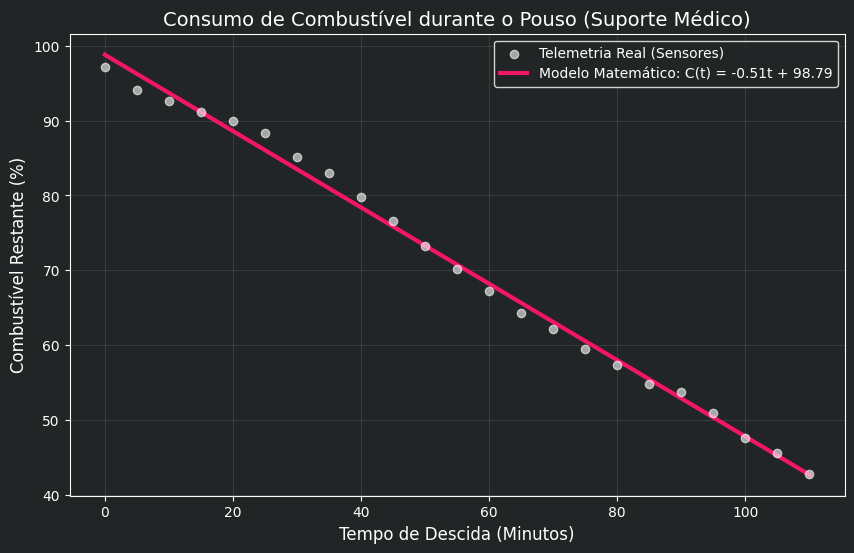

Taxa de queima média (Coeficiente 'a'): -0.51% por minuto.
Combustível Inicial (Coeficiente 'b'): 98.79%


In [ ]:
# Focando apenas no módulo "Suporte Médico" durante a queda
df_queda = df[(df['Modulo'] == 'Suporte Médico') & (df['Status'] == 'Ejetado/Descendo')].copy()

# Eixo X de "Tempo em Minutos"
df_queda['Minutos_Descida'] = np.arange(len(df_queda)) * 5

# Extraindo X (Tempo) e Y (Combustível)
x = df_queda['Minutos_Descida'].values
y = df_queda['Combustivel_%'].values

# LÓGICA MATEMÁTICA
coeficientes = np.polyfit(x, y, 1)
a, b = coeficientes[0], coeficientes[1]
y_matematico = a * x + b

# PLOTANDO O GRÁFICO
cor_fundo = '#212526'
cor_destaque = '#F21667'
cor_texto = "#FFFFFF"

fig, ax = plt.subplots(figsize=(10, 6))

fig.patch.set_facecolor(cor_fundo)
ax.set_facecolor(cor_fundo)

# Plota os dados
ax.scatter(x, y, color=cor_texto, alpha=0.6, label='Telemetria Real (Sensores)', zorder=5)

# Plota a função matemática
ax.plot(x, y_matematico, color=cor_destaque, linestyle='-', linewidth=3, 
         label=f'Modelo Matemático: C(t) = {a:.2f}t + {b:.2f}')

# Customizando os textos
ax.set_title('Consumo de Combustível durante o Pouso (Suporte Médico)', fontsize=14, color=cor_texto)
ax.set_xlabel('Tempo de Descida (Minutos)', fontsize=12, color=cor_texto)
ax.set_ylabel('Combustível Restante (%)', fontsize=12, color=cor_texto)

# Customizando as cores dos números
ax.tick_params(colors=cor_texto)
for spine in ax.spines.values():
    spine.set_color(cor_texto)

# Ajustando as cores da legenda e do grid
legend = ax.legend(facecolor=cor_fundo, edgecolor=cor_texto, labelcolor=cor_texto)
ax.grid(True, color=cor_texto, alpha=0.1)

plt.show()

print(f"Taxa de queima média (Coeficiente 'a'): {a:.2f}% por minuto.")
print(f"Combustível Inicial (Coeficiente 'b'): {b:.2f}%")

In [ ]:
# 8. SISTEMA DE PRÉ-LANÇAMENTO (Testando a Pilha / Stack - LIFO)

print("\n" + "_"*50)
print(" INICIANDO CÂMARA DE PRÉ-LANÇAMENTO (PILHA)")
print("_"*50)

pilha_camara_ar = []

# 1. Fase de Preparação (Adicionando à Pilha - PUSH)
# Simulando que o sistema aprovou e moveu 3 módulos para a câmara de lançamento
modulos_aprovados_para_hoje = [
    {"tipo": "Logística", "prioridade": 3},
    {"tipo": "Energia", "prioridade": 4},
    {"tipo": "Habitação", "prioridade": 1}
]

print("Preparando módulos para a janela de lançamento")
for mod in modulos_aprovados_para_hoje:
    pilha_camara_ar.append(mod)
    print(f"-> Módulo '{mod['tipo']}' movido para a câmara de ar.")

print(f"\nMódulos prontos para ejeção: {len(pilha_camara_ar)}")

# 2. Evento Crítico: Tempestade detectada
tempestade_detetada = True

if tempestade_detetada:
    print("\n[ALERTA METEOROLÓGICO]")
    print("Abortando janela de lançamento. Esvaziando câmara de ar (LIFO)")
    
    # 3. Esvaziando a Pilha (Retirando o último que entrou usando POP)
    # Enquanto houver módulos na câmara, retiramos do topo da pilha
    while len(pilha_camara_ar) > 0:
        modulo_retirado = pilha_camara_ar.pop() # Pop (Sem índice, tira o último)
        print(f"<- Abortado e devolvido ao armazém central: '{modulo_retirado['tipo']}'")
        
    print("\n Câmara de ar vazia e selada. Módulos protegidos no interior do Foguete.")


__________________________________________________
 INICIANDO CÂMARA DE PRÉ-LANÇAMENTO (PILHA)
__________________________________________________
Preparando módulos para a janela de lançamento
-> Módulo 'Logística' movido para a câmara de ar.
-> Módulo 'Energia' movido para a câmara de ar.
-> Módulo 'Habitação' movido para a câmara de ar.

Módulos prontos para ejeção: 3

[ALERTA METEOROLÓGICO]
Abortando janela de lançamento. Esvaziando câmara de ar (LIFO)
<- Abortado e devolvido ao armazém central: 'Habitação'
<- Abortado e devolvido ao armazém central: 'Energia'
<- Abortado e devolvido ao armazém central: 'Logística'

 Câmara de ar vazia e selada. Módulos protegidos no interior do Foguete.
